# Visual Product Finder — Part 5: Evaluation

**Previous step:** Part 4 built the search engine and saved `catalog_embeddings.npy`, `products.csv` and `model_config.json`.

**This notebook:** we evaluate the search **before** building the API on top of it, and prepare the final, portable set of engine files.

## What this notebook does

| Task | Where |
|------|-------|
| Use many different query images and show the top results visually | Sections 5 and 6 |
| Check whether results are *visually* similar or only in the same category | Section 7 (manual rating) |
| Define an evaluation metric and state its limits | Below, and Section 3 |
| Find where the search fails and why | Sections 4 to 6 |
| Handle duplicate images | Section 2 |
| Save embeddings, IDs and metadata so they work in another environment | Section 9 |

## The metric, and its limits

The dataset has no human similarity judgements, only **category labels**. So the main metric is **precision@5**: of the 5 nearest neighbours of a query, which share is in the **same category** as the query? We use every product in the catalog as a query.

> **This is only a rough proxy for visual similarity.** *Casual Shoes* and *Sports Shoes* can look alike, and two shirts of the same type can look very different. To measure the gap between "same category" and "looks similar", Section 7 adds a small **manual rating** by a human.

We make the proxy more trustworthy in three ways:

* **Chance level:** the precision a random search would reach, so that a number has a reference.
* **Leave-one-out:** a product is never counted as its own neighbour.
* **No free hits from twins:** an identical duplicate image always has the same category, so we also report precision with the query's duplicates removed.

> This notebook needs no model and no Internet. It only uses the saved embeddings and the product images.

## 1. Setup and Loading the Engine Files

In [1]:
import glob
import json
import shutil
import hashlib
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

IMAGE_DIR = Path("/kaggle/input/datasets/paramaggarwal/fashion-product-images-dataset/fashion-dataset/fashion-dataset/images")
OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")

K = 5                      # results evaluated and returned
TOP_N = 20                 # candidates kept per query (more than K, so duplicates can be skipped)
DUP_THRESHOLD = 0.999      # cosine similarity above which two images count as practically identical
MIN_TYPE_SIZE = 50         # smallest article-type group shown in the per-type table
print("Device:", device)

Device: cuda


In [2]:
def find_file(name):
    candidates = []
    for pattern in [f"/kaggle/working/{name}", f"/kaggle/input/*/{name}", f"/kaggle/input/*/*/{name}",
                    f"/kaggle/input/*/*/*/{name}", name]:
        candidates += sorted(glob.glob(pattern))
    assert candidates, f"{name} not found. Add the output of Part 4 as an Input."
    return Path(candidates[0])

E = np.load(find_file("catalog_embeddings.npy"))
products = pd.read_csv(find_file("products.csv"))
cfg = json.load(open(find_file("model_config.json")))

assert hashlib.md5(E.tobytes()).hexdigest() == cfg["catalog"]["md5"], "Checksum mismatch: wrong embedding file"
assert len(E) == len(products) == cfg["catalog"]["size"]
assert (products["embedding_row"].to_numpy() == np.arange(len(products))).all()

products["image_path"] = products["image"].apply(lambda f: IMAGE_DIR / f)
N = len(E)
print("Catalog:", N, "products | embeddings:", E.shape, "| checksum OK, rows aligned")

Catalog: 44441 products | embeddings: (44441, 2048) | checksum OK, rows aligned


Labels are converted to integer codes for fast evaluation. `chance()` is the probability that two **random** products share a label, which is the precision of a random search.

In [3]:
LABELS, NAMES = {}, {}
for col in ["masterCategory", "subCategory", "articleType", "baseColour"]:
    codes, uniques = pd.factorize(products[col].fillna("NA"))
    LABELS[col], NAMES[col] = codes, np.array(uniques)

def chance(label_codes):
    p = np.bincount(label_codes) / len(label_codes)
    return float((p ** 2).sum())

## 2. Neighbours and Duplicate Images

For each of the 44,441 products we find its `TOP_N` nearest neighbours (the product itself excluded). Everything below uses these precomputed arrays.

In [4]:
E_gpu = torch.tensor(E, device=device)
top_idx = np.zeros((N, TOP_N), dtype=np.int32)
top_sim = np.zeros((N, TOP_N), dtype=np.float32)

with torch.inference_mode():
    for s in tqdm(range(0, N, 2000)):
        e = min(s + 2000, N)
        sims = E_gpu[s:e] @ E_gpu.T
        r = torch.arange(e - s, device=device)
        sims[r, r + s] = -float("inf")                    # a product is not its own neighbour
        values, indices = sims.topk(TOP_N, dim=1)
        top_idx[s:e], top_sim[s:e] = indices.cpu().numpy(), values.cpu().numpy()
del E_gpu
print("Neighbours:", top_idx.shape)

  0%|          | 0/23 [00:00<?, ?it/s]

Neighbours: (44441, 20)


### Duplicate images

Part 4 found that about 3.6% of products have a practically identical twin. If a product's nearest neighbour is more similar than `DUP_THRESHOLD`, we link the two. Linked products form **duplicate groups**. We first check how sensitive this is to the threshold.

In [5]:
for thr in [0.99, 0.995, 0.999]:
    print(f"Nearest neighbour similarity > {thr}: {(top_sim[:, 0] > thr).mean() * 100:.2f}% of products")

src = np.nonzero(top_sim[:, 0] > DUP_THRESHOLD)[0]
dst = top_idx[src, 0]
_, group = connected_components(csr_matrix((np.ones(len(src)), (src, dst)), shape=(N, N)), directed=False)
group_size = np.bincount(group)

names = products["productDisplayName"].to_numpy()
types = LABELS["articleType"]
print()
print(f"Products in a duplicate group (threshold {DUP_THRESHOLD}): {(group_size[group] > 1).mean() * 100:.2f}%")
print(f"Linked pairs: {len(src)} | same product name: {(names[src] == names[dst]).mean() * 100:.1f}% | same article type: {(types[src] == types[dst]).mean() * 100:.1f}%")

Nearest neighbour similarity > 0.99: 4.84% of products
Nearest neighbour similarity > 0.995: 4.33% of products
Nearest neighbour similarity > 0.999: 3.59% of products

Products in a duplicate group (threshold 0.999): 3.59%
Linked pairs: 1597 | same product name: 61.8% | same article type: 98.9%


If most linked pairs share the **same product name**, they are the same product listed twice, and showing both adds nothing. If the names differ, they are different products with the same photo (for example colour variants), and hiding one would hide a real catalog entry.

### Three ways to build a result list

A boolean **mask** says which of the `TOP_N` candidates are allowed. The first `K` allowed candidates are the results.

| Variant | Rule | Purpose |
|---------|------|---------|
| **raw** | Only the query itself is excluded | The plain search |
| **honest** | Also exclude twins of the query | The **fair evaluation**: no free hits from duplicates |
| **API** | Keep only one product per duplicate group among the results | What a user sees: a twin of an uploaded photo is a correct answer, but the same picture should not fill several slots |

In [6]:
same_group_as_query = group[top_idx] == group[:, None]

def dedupe(base_mask):
    keep = np.zeros_like(base_mask)
    for j in range(TOP_N):
        seen = ((group[top_idx[:, :j]] == group[top_idx[:, j]][:, None]) & keep[:, :j]).any(axis=1)
        keep[:, j] = base_mask[:, j] & ~seen
    return keep

mask_raw = np.ones((N, TOP_N), dtype=bool)
mask_honest = ~same_group_as_query
mask_api = dedupe(mask_raw)
MASKS = {"raw": mask_raw, "honest (no query twins)": mask_honest, "API (deduplicated)": mask_api}

def get_neighbours(mask, k=K):
    order = np.argsort(~mask, axis=1, kind="stable")[:, :k]
    valid = np.take_along_axis(mask, order, axis=1)
    return np.take_along_axis(top_idx, order, axis=1), np.take_along_axis(top_sim, order, axis=1), valid

def per_query_precision(mask, label, k=K):
    nbr, _, valid = get_neighbours(mask, k)
    hit = (LABELS[label][nbr] == LABELS[label][:, None]) & valid
    return hit.sum(axis=1) / np.maximum(valid.sum(axis=1), 1)

print("Fewest allowed candidates for any query:", {n: int(m.sum(axis=1).min()) for n, m in MASKS.items()}, f"(need at least {K})")
print(f"Queries with a twin in the raw top-{K}: {(same_group_as_query[:, :K]).any(axis=1).mean() * 100:.2f}%")

Fewest allowed candidates for any query: {'raw': 20, 'honest (no query twins)': 15, 'API (deduplicated)': 8} (need at least 5)
Queries with a twin in the raw top-5: 3.59%


## 3. Precision@5 on All Queries

Every product is a query. We compare the variants at three category levels, next to the **chance level**.

In [7]:
levels = ["masterCategory", "subCategory", "articleType"]
rows = {name: {lvl: per_query_precision(m, lvl).mean() for lvl in levels} for name, m in MASKS.items()}
rows["(chance level)"] = {lvl: chance(LABELS[lvl]) for lvl in levels}
precision_df = pd.DataFrame(rows).T.round(4)
precision_df

,masterCategory,subCategory,articleType
raw,0.9909,0.9402,0.8186
honest (no query twins),0.9909,0.9397,0.8169
API (deduplicated),0.9909,0.9398,0.8177
(chance level),0.3423,0.1650,0.0510


**How to read it:**

* **raw vs honest:** the gap is the part of the score that came from identical twins. A small gap means duplicates did not distort our earlier numbers much.
* All values should be far above the **chance level**. `articleType` has 143 groups, so chance there is very low.
* We use **honest** as our main number from here on.

## 4. Where Does the Search Fail?

### 4.1 Precision by article type

Only types with at least `MIN_TYPE_SIZE` products are listed (small groups give unreliable numbers). **Lift** is the precision divided by the share of that type in the catalog, i.e. how much better than random the search is for that type.

In [8]:
p_type = per_query_precision(mask_honest, "articleType")

per_type = (pd.DataFrame({"articleType": NAMES["articleType"][types], "precision": p_type})
            .groupby("articleType").agg(n=("precision", "size"), precision=("precision", "mean")))
per_type["lift"] = per_type["precision"] / (per_type["n"] / N)
per_type = per_type[per_type["n"] >= MIN_TYPE_SIZE].sort_values("precision")

print(f"{len(per_type)} article types with at least {MIN_TYPE_SIZE} products. Weakest:")
display(per_type.head(10).round(3))
print("Strongest:")
display(per_type.tail(5).round(3))

70 article types with at least 50 products. Weakest:


,n,precision,lift
articleType,,,
Tunics,229,0.110,21.356
Free Gifts,91,0.169,82.646
Sports Sandals,67,0.218,144.540
Kurtis,234,0.227,43.178
Lounge Pants,61,0.321,234.089
Flats,500,0.350,31.144
Face Moisturisers,61,0.380,277.084
Laptop Bag,82,0.385,208.854
Dresses,464,0.432,41.407


Strongest:


,n,precision,lift
articleType,,,
Bra,477,0.986,91.879
Socks,686,0.988,64.027
Ties,263,0.990,167.307
Accessory Gift Set,111,0.995,398.205
Nail Polish,329,0.996,134.504


A low value does **not** automatically mean a bad search. It can mean the category has neighbours that are almost the same thing. The next table checks exactly that.

### 4.2 Which "errors" are really boundary cases?

For every wrong result (a different article type than the query) we count the pair *(query type → returned type)*. If a few near-synonym pairs dominate, many "errors" are label ambiguity and not search failures.

In [9]:
nbr, sim, valid = get_neighbours(mask_honest)
wrong = valid & (types[nbr] != types[:, None])
qi, ki = np.nonzero(wrong)

pairs = pd.DataFrame({"query type": NAMES["articleType"][types[qi]],
                      "returned type": NAMES["articleType"][types[nbr[qi, ki]]]})
confusion = pairs.value_counts().reset_index(name="count")
confusion["% of all errors"] = (confusion["count"] / len(pairs) * 100).round(2)

print(f"Wrong results: {len(pairs)} | distinct pairs: {len(confusion)} | top 10 pairs = {confusion['% of all errors'].head(10).sum():.1f}% of all errors")
confusion.head(10)

Wrong results: 40678 | distinct pairs: 1530 | top 10 pairs = 31.1% of all errors


,query type,returned type,count,% of all errors
0,Casual Shoes,Sports Shoes,2162,5.31
1,Sports Shoes,Casual Shoes,2065,5.08
2,Tops,Tshirts,1881,4.62
3,Tshirts,Tops,1737,4.27
4,Heels,Flats,1088,2.67
5,Flats,Heels,920,2.26
6,Casual Shoes,Formal Shoes,894,2.20
7,Kurtis,Kurtas,642,1.58
8,Tops,Kurtas,638,1.57
9,Kurtas,Kurtis,619,1.52


**How to judge:** read the pairs. Pairs like *Casual Shoes → Sports Shoes* or *Tops → Tshirts* are ambiguous labels, so those results are often acceptable. A pair like *Watches → Wallets* would be a real failure. Count how many of the top pairs you consider acceptable and write that down.

## 5. Looking at Results: Different Query Images

We take one query from each of the 8 most common article types, so that the queries are as different as possible. A **green** title means the result has the same article type, **red** means it does not (which is not necessarily wrong). The query itself is excluded.

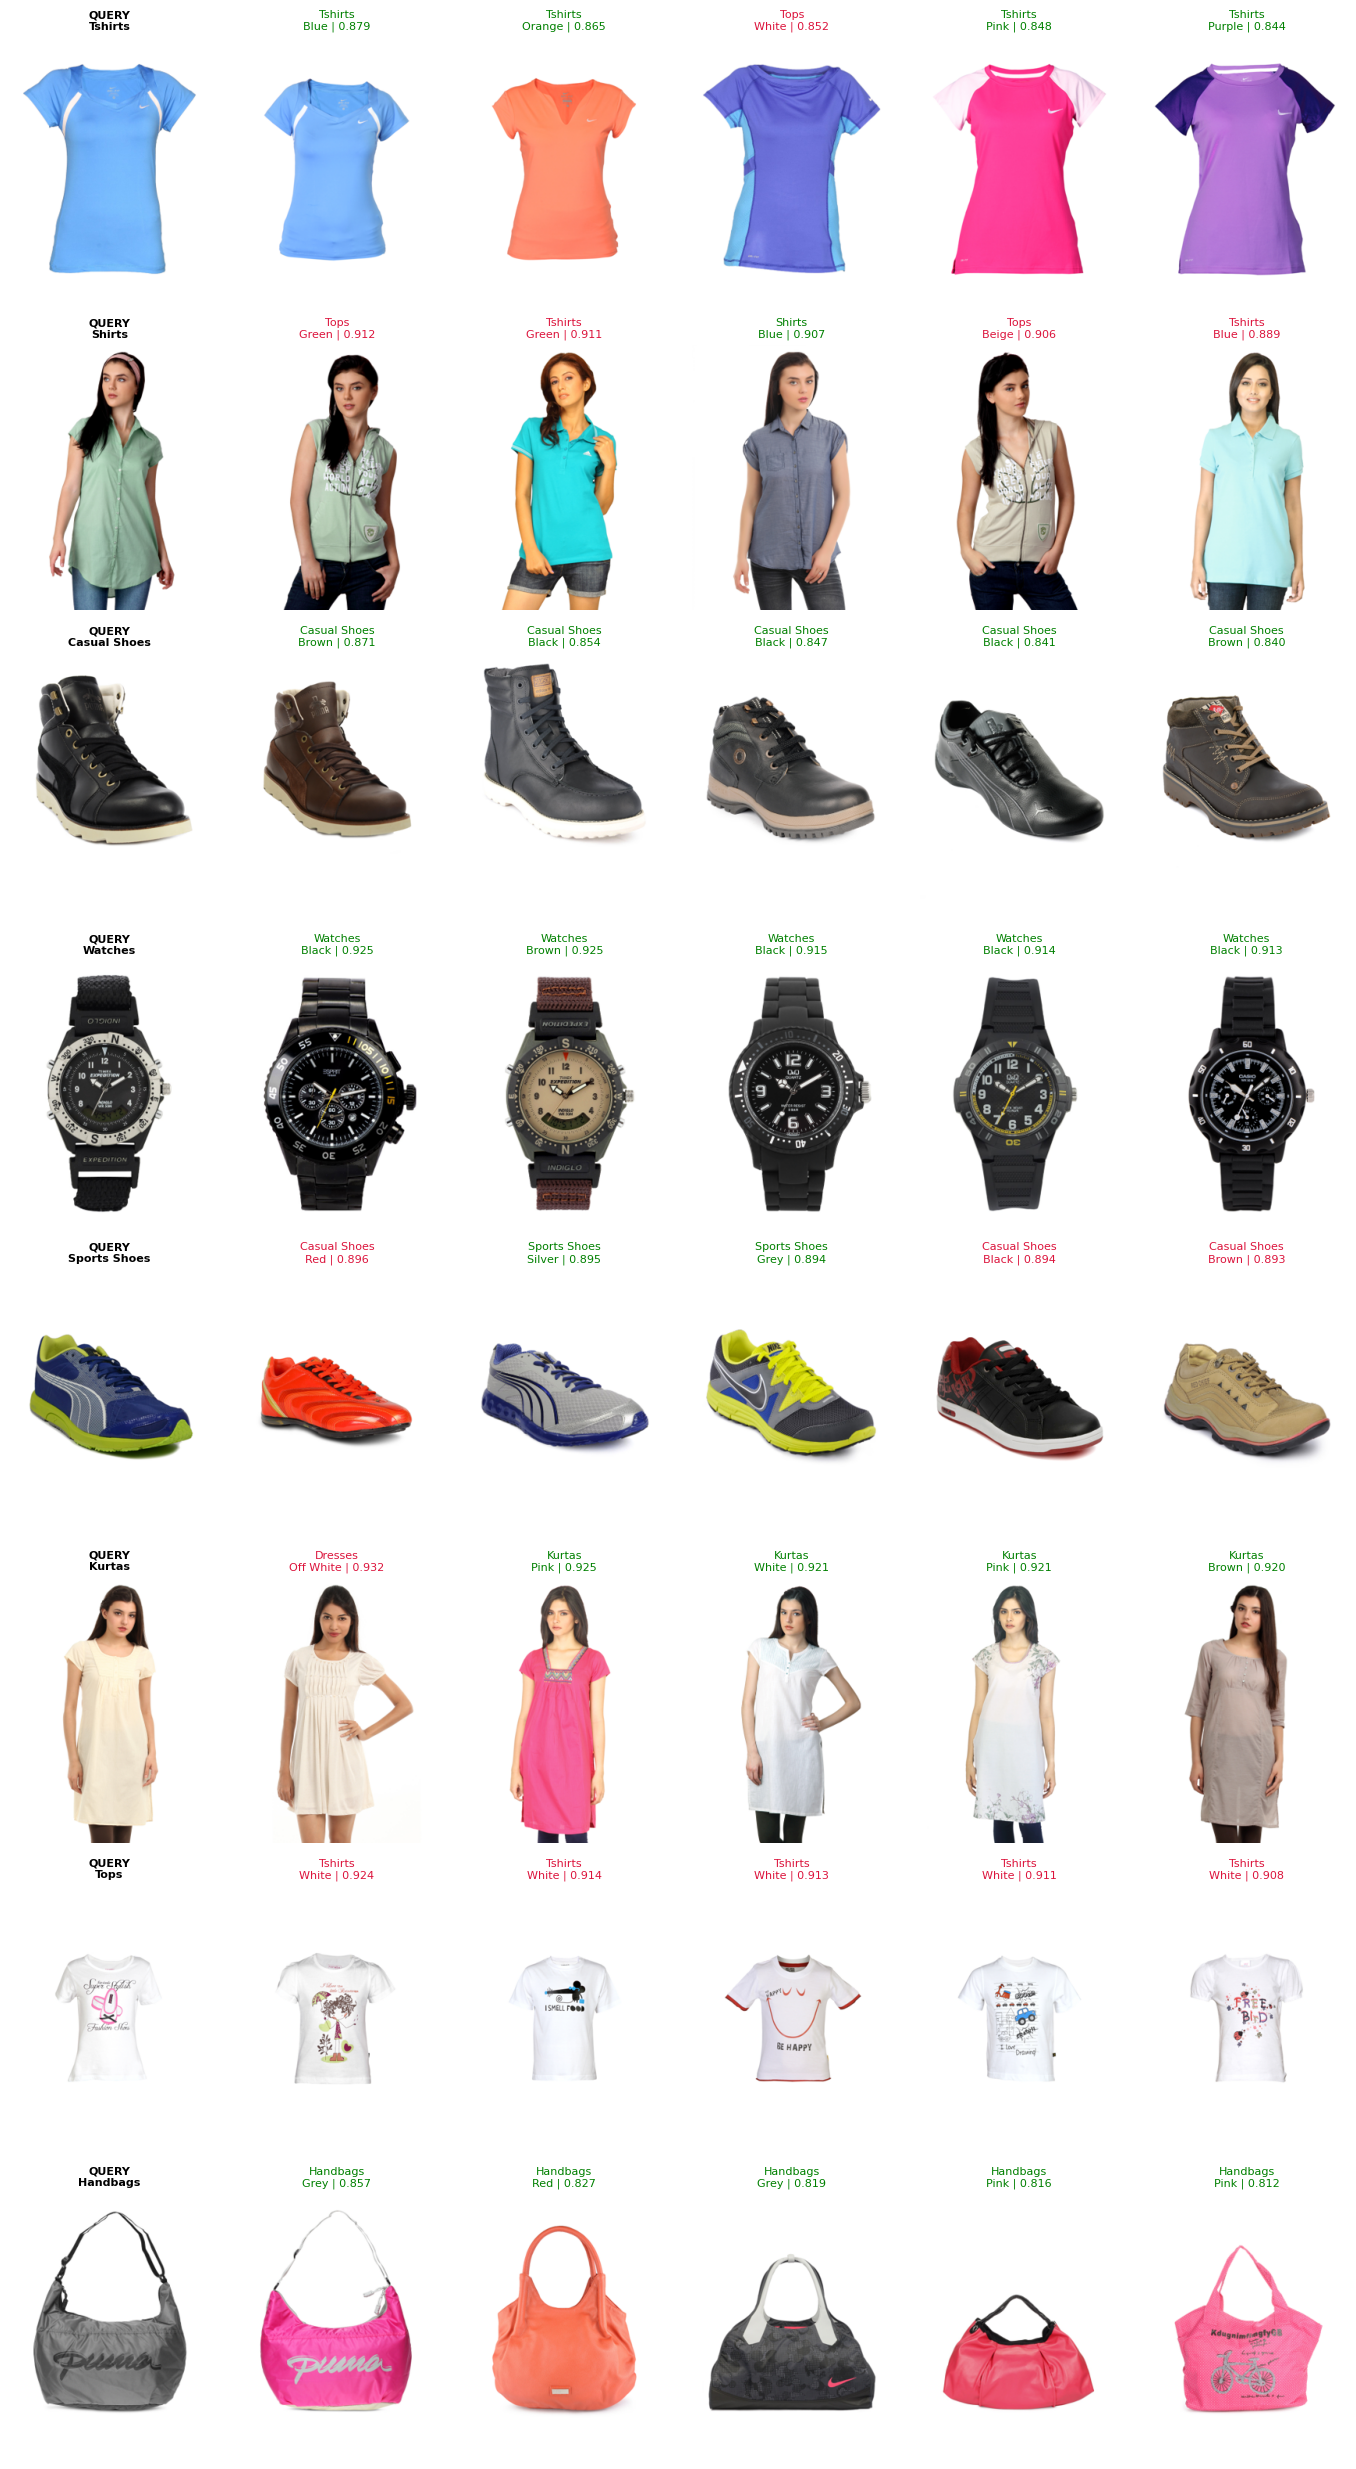

In [10]:
def load_thumb(path, size=(260, 340)):
    im = Image.open(path)
    im.draft("RGB", size)
    im = im.convert("RGB")
    im.thumbnail(size)
    return im

def show_queries(rows, mask, k=K):
    nbr, sim, valid = get_neighbours(mask, k)
    fig, axes = plt.subplots(len(rows), k + 1, figsize=(2.3 * (k + 1), 3.1 * len(rows)))
    axes = np.atleast_2d(axes)
    for r, q in enumerate(rows):
        q_t = products.loc[q, "articleType"]
        for c, idx in enumerate([q] + list(nbr[q])):
            ax = axes[r, c]
            ax.imshow(load_thumb(products.loc[idx, "image_path"]))
            ax.axis("off")
            t = products.loc[idx, "articleType"]
            if c == 0:
                ax.set_title(f"QUERY\n{t}", fontsize=8, fontweight="bold")
            else:
                ax.set_title(f"{t}\n{products.loc[idx, 'baseColour']} | {sim[q, c - 1]:.3f}",
                             fontsize=8, color="green" if t == q_t else "crimson")
    plt.tight_layout()
    plt.show()

rng = np.random.RandomState(SEED)
top_types = products["articleType"].value_counts().index[:8]
diverse = [int(rng.choice(np.nonzero((products["articleType"] == t).to_numpy())[0])) for t in top_types]
show_queries(diverse, mask_honest)

Ask for each row: are the results the right kind of product? Do colour, pattern and shape match? For clothing on models, are results alike because of the **garment** or because of the **pose and framing**?

### Looking at failures

Random queries where **none** of the 5 results has the right article type (types with enough products only). Is the result *wrong*, or just *labelled differently*?

Queries with 0 of 5 correct: 1650 (3.8% of queries in large types)


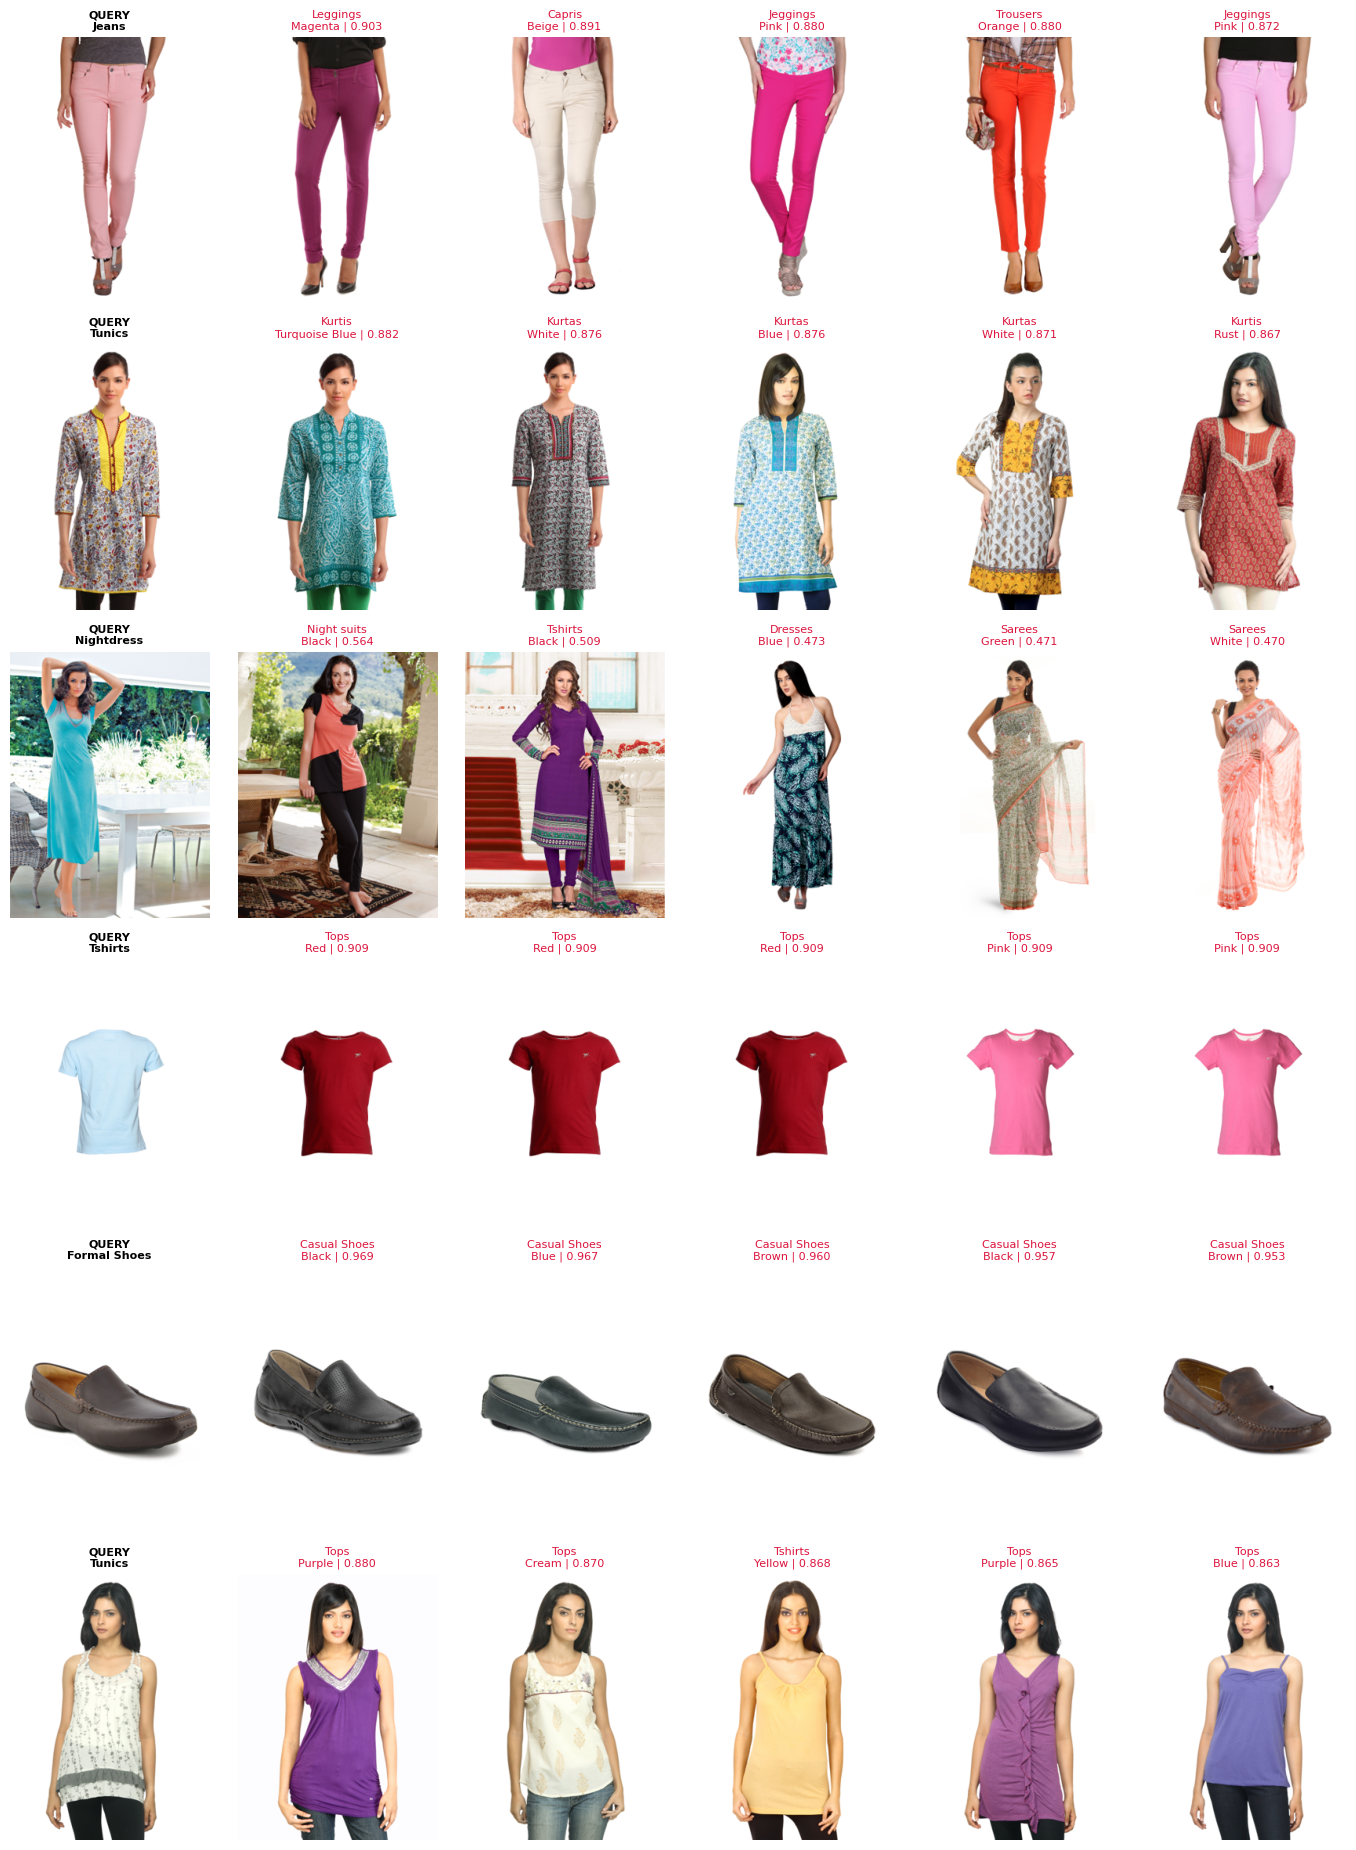

In [11]:
big_type = products["articleType"].map(per_type["n"]).fillna(0).to_numpy() >= MIN_TYPE_SIZE
failures = np.nonzero((p_type == 0) & big_type)[0]
print(f"Queries with 0 of {K} correct: {len(failures)} ({len(failures) / big_type.sum() * 100:.1f}% of queries in large types)")
show_queries(rng.choice(failures, size=6, replace=False), mask_honest)

## 6. Garment or Pose? A Test of the Suspicion

In Parts 3 and 4, results for clothing looked alike in **pose and framing** but not always in colour. If the embedding mostly captures the garment, neighbours should often share the **colour**; if it mostly captures pose and framing, colour should match **less**.

We compare colour agreement between **Apparel** (photographed on models) and **Footwear** and **Accessories** (mostly photographed alone), against the chance level **inside each group**.

> **A proxy, not a proof.** Colour distributions and item variety differ between groups, so a difference can have other causes. Report the result as *consistent with* or *not consistent with* the suspicion.

In [12]:
colour = LABELS["baseColour"]
nbr, sim, valid = get_neighbours(mask_honest)
colour_hit = ((colour[nbr] == colour[:, None]) & valid).sum(axis=1) / np.maximum(valid.sum(axis=1), 1)

frame = pd.DataFrame({"group": products["masterCategory"], "hit": colour_hit, "colour": colour})
rows = []
for group_name, sub in frame.groupby("group"):
    if len(sub) >= 500:
        ch = chance(sub["colour"].to_numpy())
        rows.append({"group": group_name, "n": len(sub), "colour@5": sub["hit"].mean(), "chance": ch, "lift": sub["hit"].mean() / ch})
colour_df = pd.DataFrame(rows).set_index("group").round(3)
colour_df

,n,colour@5,chance,lift
group,,,,
Accessories,11289,0.348,0.126,2.762
Apparel,21395,0.325,0.091,3.566
Footwear,9222,0.393,0.162,2.427
Personal Care,2404,0.258,0.071,3.640


## 7. Manual Rating: Similar Looking, or Only Same Category?

The category metric cannot tell whether results *look* similar. So we measure that directly with a small human rating.

**How it works:** 20 queries (2 from each of the 10 most common article types) are shown **without category labels or scores**, so that your judgement is not influenced by them. For every result, enter **1** if a shopper would accept it as a similar product (same kind of item, similar shape, style or colour), and **0** if not. Rate only by looking at the pictures. It takes about 10 minutes.

Then we compare your rating with the category metric on the **same** results. The 2×2 table shows four cases, among them the two that matter most:

* **same category, not similar** (the proxy overstates quality)
* **different category, but similar** (the proxy understates quality)

> Your judgement is subjective and 20 queries are few, so treat the result as an estimate. You can skip this section: the notebook still runs.

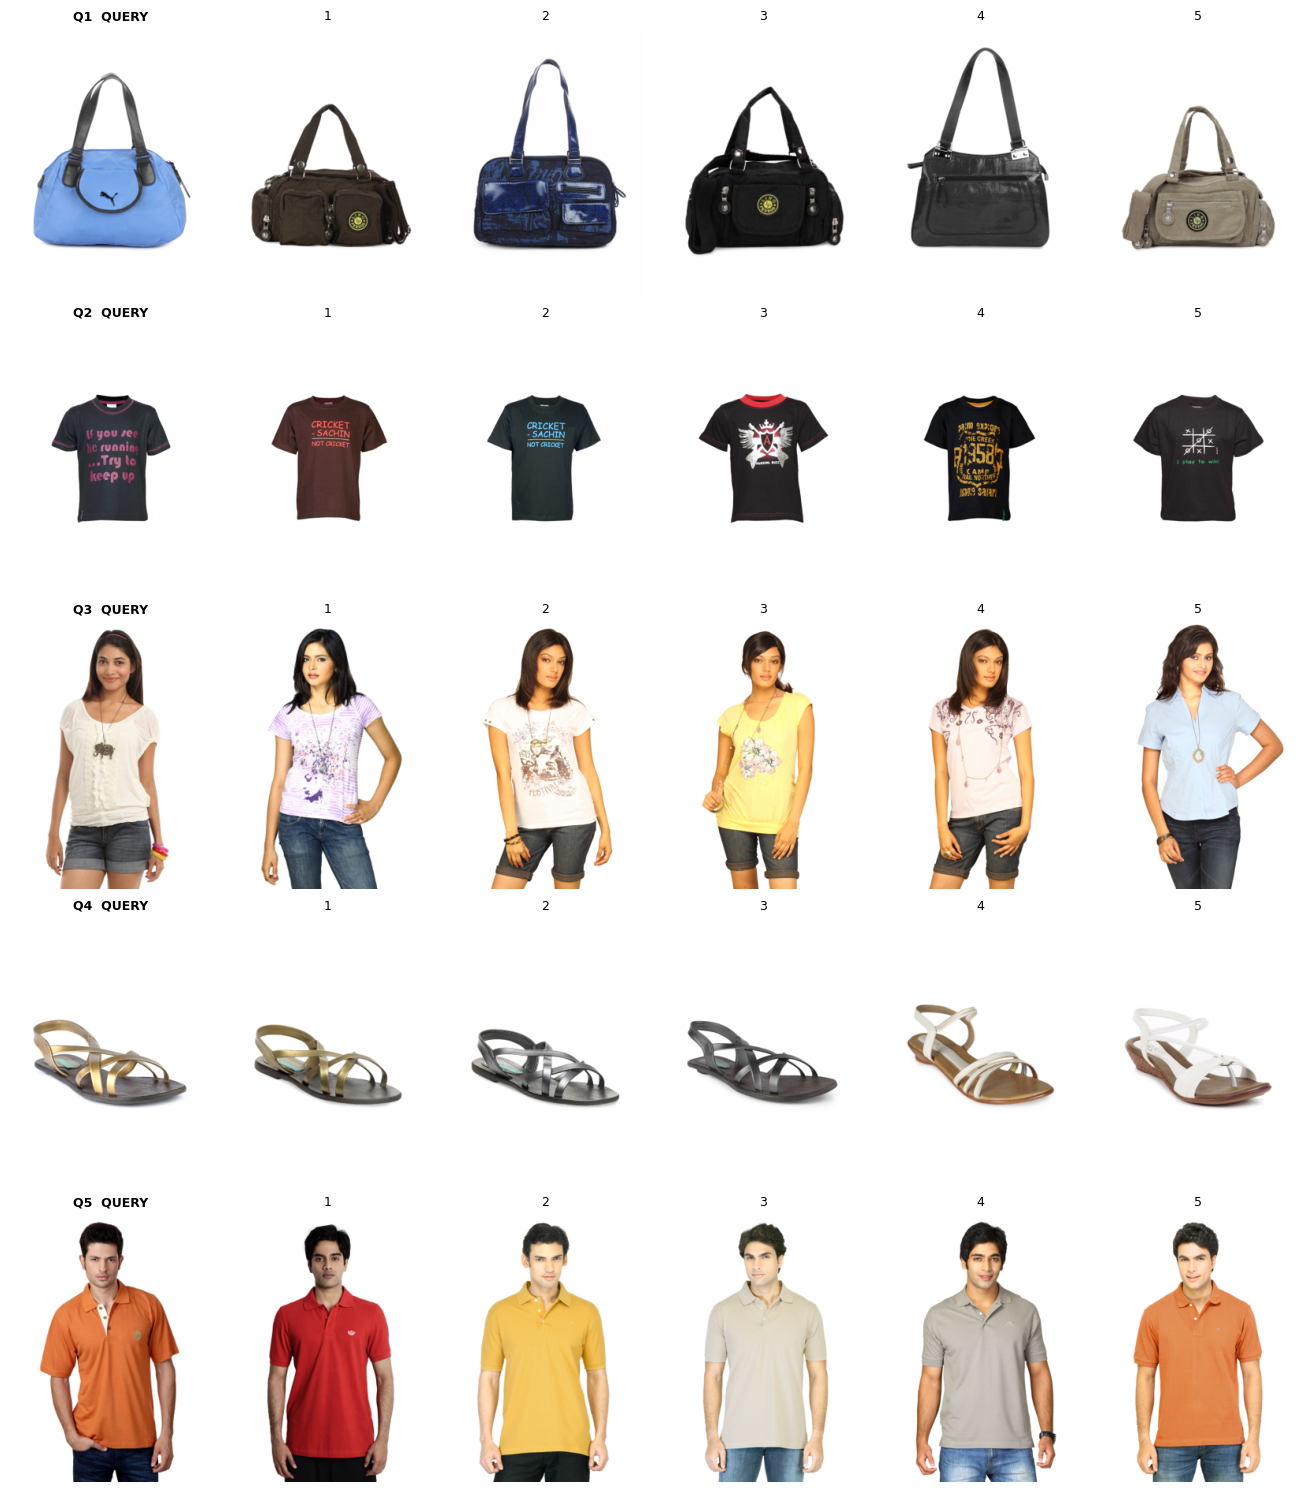

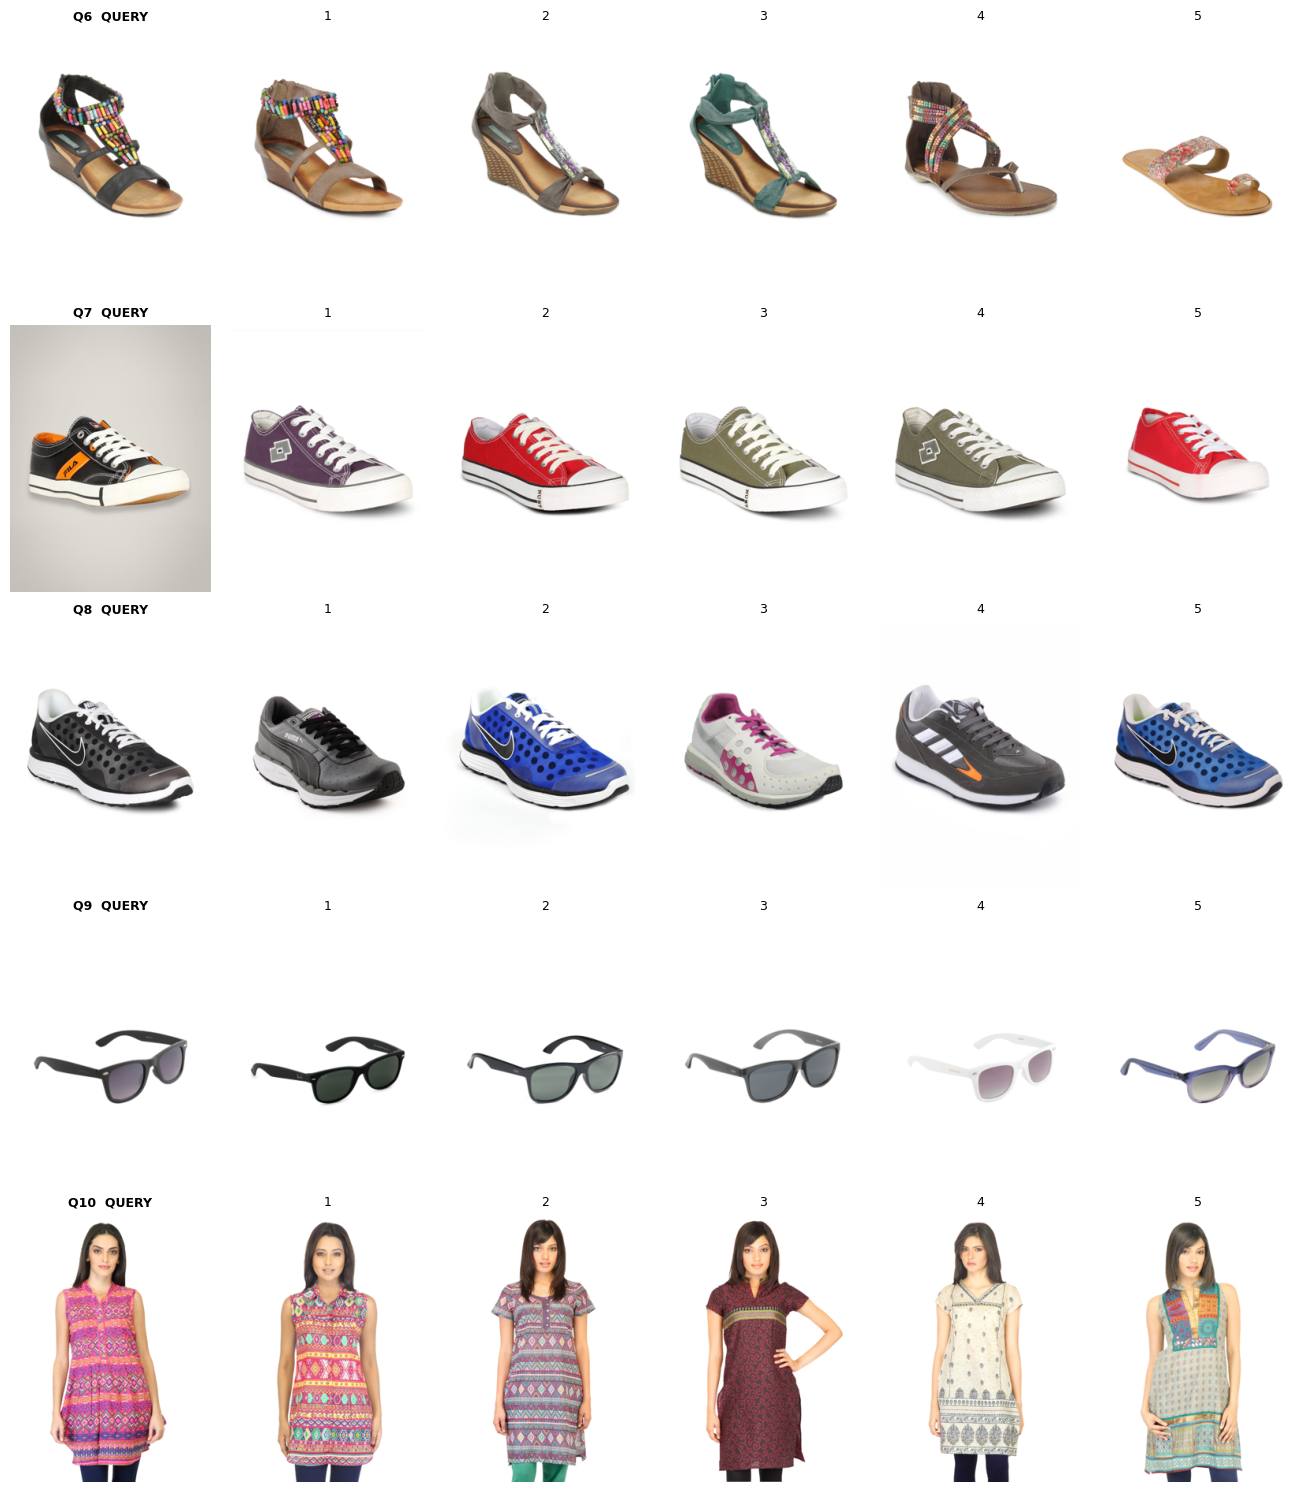

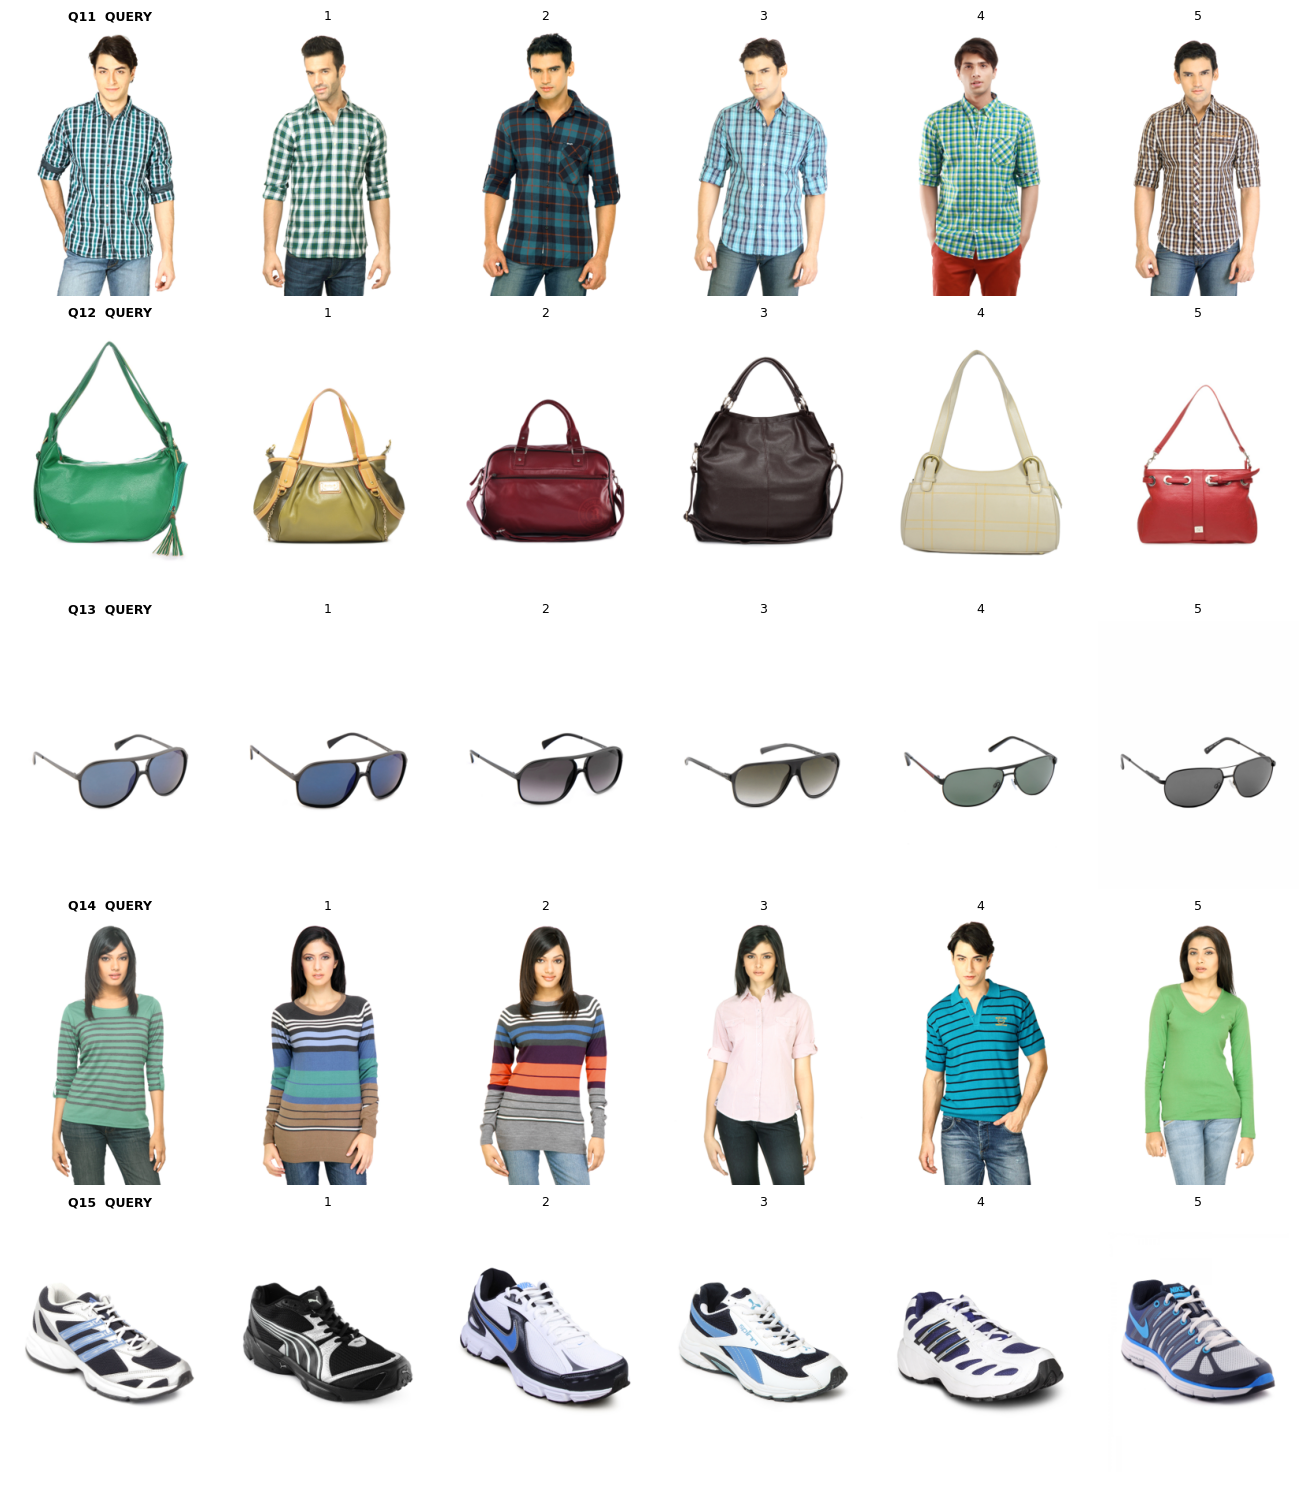

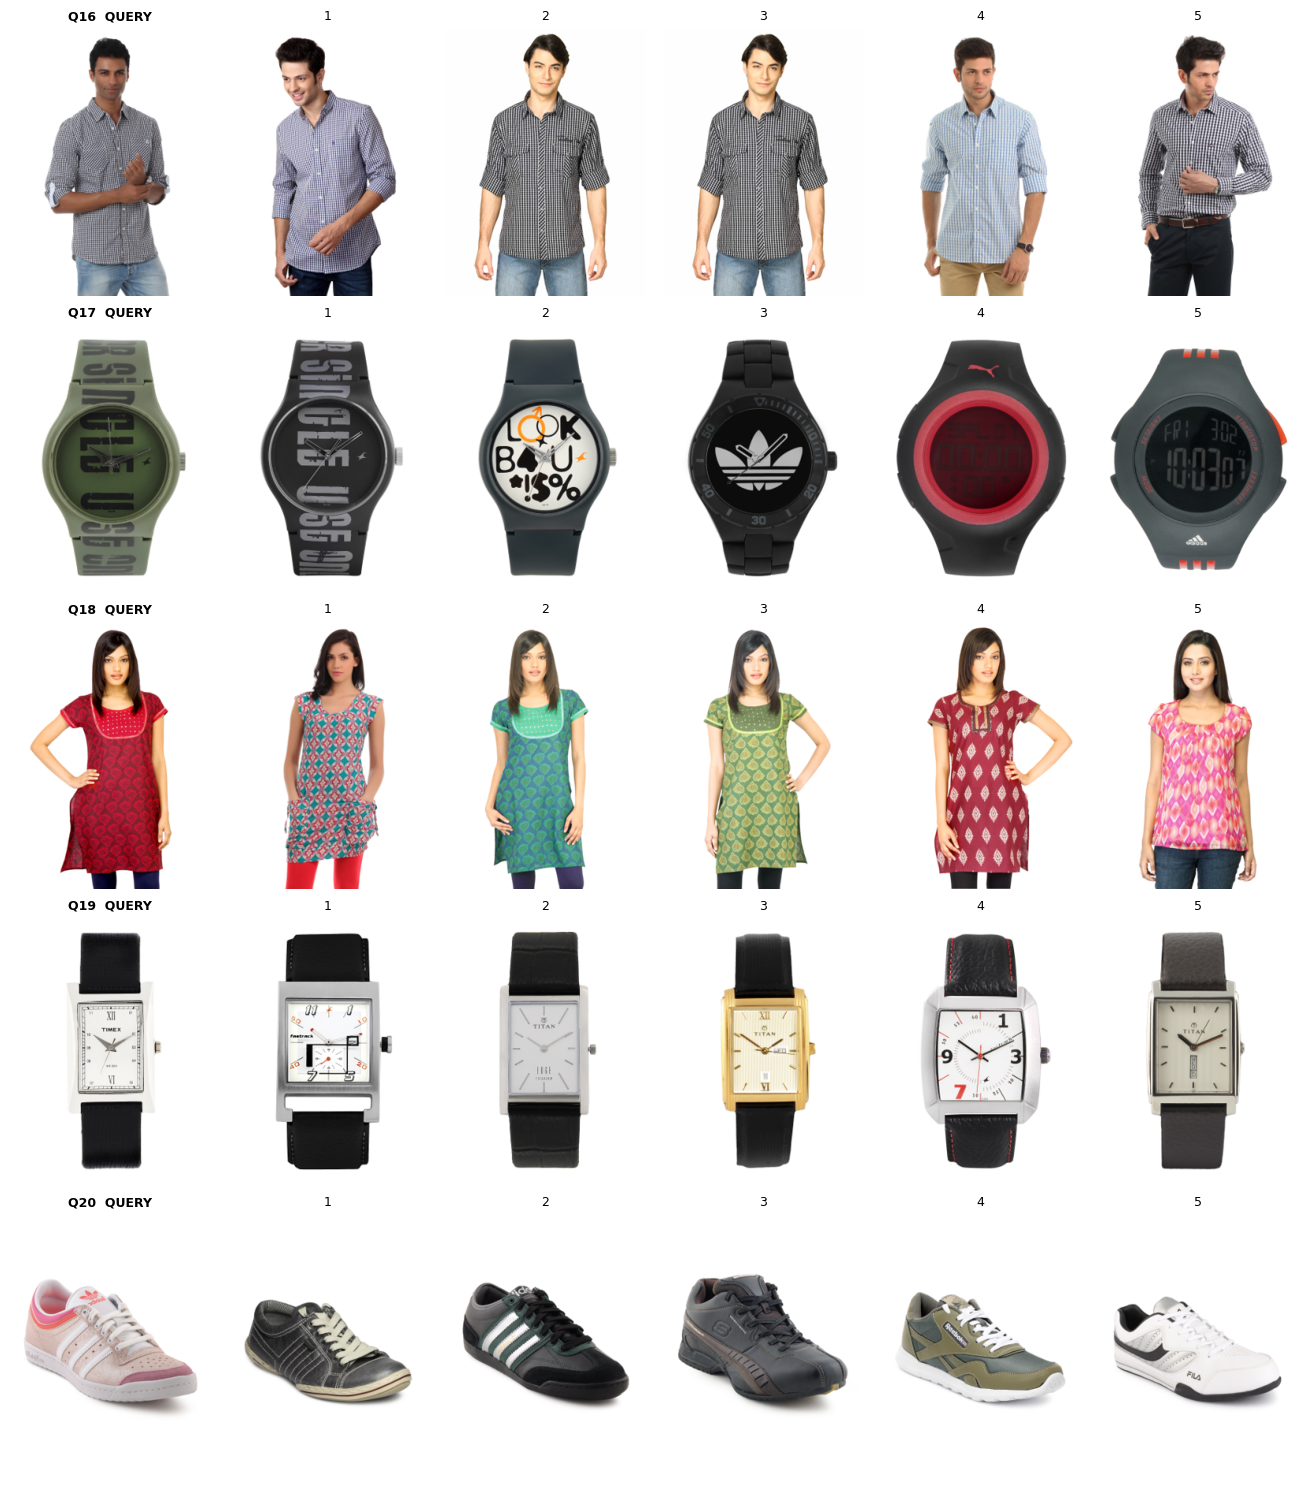

In [13]:
top10 = products["articleType"].value_counts().index[:10]
rng2 = np.random.RandomState(SEED + 7)
rating_queries = []
for t in top10:
    rating_queries += [int(q) for q in rng2.choice(np.nonzero((products["articleType"] == t).to_numpy())[0], size=2, replace=False)]
rng2.shuffle(rating_queries)

nbr, _, _ = get_neighbours(mask_honest)
for start in range(0, len(rating_queries), 5):
    chunk = rating_queries[start:start + 5]
    fig, axes = plt.subplots(len(chunk), K + 1, figsize=(2.2 * (K + 1), 3.0 * len(chunk)))
    for r, q in enumerate(chunk):
        for c, idx in enumerate([q] + list(nbr[q])):
            axes[r, c].imshow(load_thumb(products.loc[idx, "image_path"]))
            axes[r, c].axis("off")
            axes[r, c].set_title(f"Q{start + r + 1}  QUERY" if c == 0 else f"{c}", fontsize=9, fontweight="bold" if c == 0 else None)
    plt.tight_layout()
    plt.show()

Fill in your ratings below: one list of five 0/1 values per query, in the order the results are shown (left to right). Remove the `#` in front of a line to use it. You may rate only some queries.

In [14]:
ratings = {
    # 1: [1, 1, 1, 1, 1],
    # 2: [1, 0, 1, 1, 0],
    # 3: [],  4: [],  5: [],  6: [],  7: [],  8: [],  9: [], 10: [],
    # 11: [], 12: [], 13: [], 14: [], 15: [], 16: [], 17: [], 18: [], 19: [], 20: [],
}

In [15]:
ratings = {q: r for q, r in ratings.items() if r}
if not ratings:
    print("No ratings entered: this step is skipped.")
else:
    rows = []
    for qn, r in list(ratings.items()):
        if len(r) != K or not set(r) <= {0, 1}:          # empty or malformed entries are skipped, not fatal
            if r:
                print(f"Q{qn}: skipped (need {K} values, each 0 or 1)")
            ratings.pop(qn)
            continue
        q = rating_queries[qn - 1]
        same_type = types[nbr[q]] == types[q]
        rows += [{"Q": qn, "visual": v, "category": int(c)} for v, c in zip(r, same_type)]
    rated = pd.DataFrame(rows)
    if rated.empty:
        print("No valid ratings found: this step is skipped.")
        ratings = {}
    else:
        print(f"Rated queries: {rated['Q'].nunique()} | rated results: {len(rated)}")
        print(f"Precision@5 by your visual rating : {rated['visual'].mean():.3f}")
        print(f"Precision@5 by article type        : {rated['category'].mean():.3f}  (same results)")
        display(pd.crosstab(rated["category"].map({1: "same article type", 0: "different article type"}),
                            rated["visual"].map({1: "looks similar", 0: "does not look similar"})))

No ratings entered: this step is skipped.


**How to read it:**

* If the visual precision is **higher** than the category precision, many "wrong" results were actually fine, and the proxy **understates** the quality.
* If it is **lower**, some same-category results do not look alike, and the proxy **overstates** the quality.
* The crosstab shows which of the two cases is more common.

## 8. Saving Evaluation Results

In [16]:
per_type.round(4).to_csv(OUTPUT_DIR / "per_type_precision.csv")
confusion.head(50).to_csv(OUTPUT_DIR / "top_confusions.csv", index=False)

summary = {
    "queries": int(N), "k": K, "duplicate_threshold": DUP_THRESHOLD,
    "precision_at_5": precision_df.to_dict(orient="index"),
    "share_in_duplicate_group_pct": round(float((group_size[group] > 1).mean() * 100), 2),
    "colour_agreement_by_group": colour_df.to_dict(orient="index"),
}
if ratings:
    summary["manual_rating"] = {"rated_results": int(len(rated)), "visual_precision_at_5": round(float(rated["visual"].mean()), 3),
                                "category_precision_at_5_same_results": round(float(rated["category"].mean()), 3)}
with open(OUTPUT_DIR / "eval_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print("Saved: per_type_precision.csv, top_confusions.csv, eval_summary.json")

Saved: per_type_precision.csv, top_confusions.csv, eval_summary.json


## 9. The Final Engine Files (Portable Bundle)

The API will load **one folder** with everything it needs. We copy the three engine files from Part 4 into `vpf_artifacts/`, add the search settings, and write a **manifest** with sizes and checksums. The order of rows is **never changed**: row *i* of `catalog_embeddings.npy` describes row *i* of `products.csv` (column `embedding_row`).

| File | Content |
|------|---------|
| `catalog_embeddings.npy` | `(N, 2048)` float32, L2-normalized |
| `products.csv` | Product IDs and metadata, same row order |
| `model_config.json` | Weights, preprocessing and precision needed to embed a **query** like the catalog |
| `search_settings.json` | Number of results and the duplicate rule (same values as in this evaluation) |
| `manifest.json` | File sizes and checksums |

> The embedding file is about 364 MB. For GitHub use Git LFS or GitHub Releases.

In [17]:
BUNDLE = OUTPUT_DIR / "vpf_artifacts"
BUNDLE.mkdir(exist_ok=True)

for name in ["catalog_embeddings.npy", "products.csv", "model_config.json"]:
    shutil.copy(find_file(name), BUNDLE / name)

search_settings = {"k": K, "candidates": TOP_N, "deduplicate_results": True, "duplicate_threshold": DUP_THRESHOLD}
with open(BUNDLE / "search_settings.json", "w") as f:
    json.dump(search_settings, f, indent=2)

manifest = {p.name: {"bytes": p.stat().st_size, "md5": hashlib.md5(p.read_bytes()).hexdigest()}
            for p in sorted(BUNDLE.iterdir()) if p.name != "manifest.json"}
with open(BUNDLE / "manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

for name, info in manifest.items():
    print(f"{name:26s} {info['bytes'] / 1024**2:8.1f} MB  md5 {info['md5'][:10]}...")

catalog_embeddings.npy        347.2 MB  md5 be144e25fc...
model_config.json               0.0 MB  md5 2a2bc05128...
products.csv                    4.9 MB  md5 bee074e1c0...
search_settings.json            0.0 MB  md5 712ce5f94a...


### Test: can the bundle be used on its own?

A function that uses **only NumPy, pandas and JSON** (no model, no notebook variables) loads the bundle, checks it, and searches. This is what the API will do. We compare its results with the neighbours computed earlier in this notebook.

In [18]:
def load_bundle(folder):
    folder = Path(folder)
    E_ = np.load(folder / "catalog_embeddings.npy")
    P_ = pd.read_csv(folder / "products.csv")
    cfg_ = json.load(open(folder / "model_config.json"))
    manifest_ = json.load(open(folder / "manifest.json"))
    assert hashlib.md5(E_.tobytes()).hexdigest() == cfg_["catalog"]["md5"], "embeddings do not match model_config.json"
    assert manifest_["catalog_embeddings.npy"]["bytes"] == (folder / "catalog_embeddings.npy").stat().st_size
    assert len(E_) == len(P_) == cfg_["catalog"]["size"]
    assert (P_["embedding_row"].to_numpy() == np.arange(len(P_))).all() and P_["id"].is_unique
    assert np.isfinite(E_).all()
    return E_, P_, cfg_

E2, P2, cfg2 = load_bundle(BUNDLE)

checked = np.random.RandomState(SEED).choice(N, 50, replace=False)
ok = 0
for q in checked:
    s = E2 @ E2[q]
    s[q] = -np.inf
    best = np.sort(s)[::-1][:K]
    ok += int(np.allclose(best, top_sim[q, :K], atol=1e-5))
print(f"Bundle loaded and verified: {len(E2)} products, ids unique, rows aligned, checksum OK")
print(f"Search results identical to the notebook's results for {ok}/{len(checked)} test queries")

Bundle loaded and verified: 44441 products, ids unique, rows aligned, checksum OK
Search results identical to the notebook's results for 50/50 test queries


## 10. Summary

> Fill in the values and your own observations after running the notebook.

### Precision@5, every product as a query (rough proxy)

| Variant | masterCategory | subCategory | articleType |
|---------|----------------|-------------|-------------|
| raw | ... | ... | ... |
| honest (no query twins) | ... | ... | ... |
| API (deduplicated) | ... | ... | ... |
| chance level | ... | ... | ... |

### Visual rating vs. category metric (manual, ... queries)

| | Value |
|---|---|
| Precision@5 by visual rating | ... |
| Precision@5 by article type (same results) | ... |
| Same type, not similar / different type, similar | ... / ... |

### Where it fails

* **Weakest article types:** ...
* **Most common "errors":** ... (how many are label ambiguity?)
* **Failure examples:** ...

### Duplicates

* Share of products in a duplicate group: ...%, same product name in ...% of pairs
* Rule for the API: ...

### Garment or pose?

* Colour lift: Apparel ..., Footwear ..., Accessories ...
* Conclusion (*consistent with* / *not consistent with* the suspicion): ...

## Known limitations

* The embedding model (ResNet50, ImageNet weights) was never trained for fashion similarity.
* Precision is measured against category labels, a proxy for visual similarity; the manual rating covers only a small sample.
* Search quality drops for cropped or low-resolution photos (Part 4).
* For clothing on models, similarity may be influenced by pose and framing (Section 6).
* The catalog contains duplicate images.

## Output

`vpf_artifacts/` contains the files the API loads. Row order is identical in the embeddings and in `products.csv`.

## What comes next (outside Kaggle)

This is the **last notebook of the project on Kaggle**. The remaining steps are an API and a website, which have to run as a web service and cannot be hosted inside a notebook:

* **API:** a FastAPI service that loads the files in `vpf_artifacts/`, embeds an uploaded image with the preprocessing described in `model_config.json`, searches, applies the duplicate rule from `search_settings.json`, and returns the top results as JSON
* **Website:** a web interface where a user uploads an image and sees similar products, connected to the API
* **GitHub:** the code, the README and the instructions to run everything will be published at [github.com/GitT456](https://github.com/GitT456)

### Notebooks of this project

| Part | Notebook | Content |
|------|----------|---------|
| 1 | VPF 01 · Fashion Dataset EDA | Data exploration and validation |
| 2 | VPF 02 · Image Preprocessing | Preprocessing pipeline for ResNet50 |
| 3 | VPF 03 · ResNet50 Embeddings | Feature extraction and preprocessing comparison |
| 4 | VPF 04 · Search Engine | Full-catalog embeddings and cosine-similarity search |
| 5 | VPF 05 · Evaluation (this notebook) | Evaluation, limitations and the final engine files |